# Remittance Project

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [88]:
# World Bank, Personal Remittances, received (% of GDP)
remitt_df = pd.read_csv("wbremitt.csv", skiprows=4)

# Adolescents out of school (% of lower secondary...)
oos_df = pd.read_csv("oos.csv",skiprows=4)

# GDP per capita, PPP (current international $)
GDP_PPPdf= pd.read_csv("GDPPPP.csv", skiprows = 4)

# Population, total
POP_df = pd.read_csv("POP/POP.csv", skiprows=4)

# School enrollment, secondary (% gross)
gross_sec_df = pd.read_csv("gross_secenroll/grosssec.csv", skiprows = 4)

# Government expenditure on education, total (% of GDP)
govspend_df = pd.read_csv("GOVSpend/govspend.csv", skiprows = 4)

In [89]:
remitt_df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.815418,1.126929,1.023551,1.421505,1.240632,1.150685,1.039997,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.040153,1.210944,1.265702,1.288841,1.370416,1.520609,1.627284,1.968061,1.467600,NaN
2,Afghanistan,AFG,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.387093,4.450986,4.407428,3.953297,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.936272,4.828054,3.563084,3.179705,3.123878,3.268120,3.823394,5.504774,NaN,NaN
4,Angola,AGO,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001656,0.001745,0.004244,0.013763,0.016135,0.010922,0.011379,0.049514,0.042334,NaN


In [90]:
# Remove the Unnamed: 70 which does not include any data, and melt remitt. Also drop indicator name and code, as they will be represented by value_name

remitt_df = remitt_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
remitt_long = pd.melt(remitt_df, id_vars=["Country Name", "Country Code"],value_name='remitt', var_name = "year" )

remitt_long['year'].unique()


<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [91]:
# repeat for each variable

oos_df = oos_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
oos_long = pd.melt(oos_df, id_vars=["Country Name", "Country Code"],value_name='out_of_school', var_name = "year" )

oos_long['year'].unique()


<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [92]:
GDP_PPPdf = GDP_PPPdf.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
GDP_long = pd.melt(GDP_PPPdf, id_vars=["Country Name", "Country Code"],value_name='gdp_ppp', var_name = "year" )

GDP_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [93]:
POP_df = POP_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
POP_long = pd.melt(POP_df, id_vars=["Country Name", "Country Code"],value_name='population', var_name = "year" )

POP_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [94]:
gross_sec_df = gross_sec_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
sec_enroll_long = pd.melt(gross_sec_df, id_vars=["Country Name", "Country Code"],value_name='secondary_enroll_gross', var_name = "year" )

sec_enroll_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [95]:
govspend_df = govspend_df.drop(columns=["Unnamed: 70","Indicator Name", "Indicator Code"])
gov_spend_long = pd.melt(govspend_df, id_vars=["Country Name", "Country Code"],value_name='gov_edu_spend', var_name = "year" )

gov_spend_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [96]:
indexed = []
for i in [remitt_long, oos_long, GDP_long, POP_long, sec_enroll_long, gov_spend_long]:
    indexed.append(i.set_index(["Country Name", "Country Code", "year"]))

merged = pd.concat(indexed, axis=1)
merged = merged.reset_index()


In [97]:
merged["year"] = merged["year"].astype(int)

merged

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
0,Aruba,ABW,1960,NaN,NaN,NaN,54922.0,NaN,NaN
1,Africa Eastern and Southern,AFE,1960,NaN,NaN,NaN,130075728.0,NaN,NaN
2,Afghanistan,AFG,1960,NaN,NaN,NaN,9035043.0,NaN,NaN
3,Africa Western and Central,AFW,1960,NaN,NaN,NaN,97630925.0,NaN,NaN
4,Angola,AGO,1960,NaN,NaN,NaN,5231654.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17551,Kosovo,XKX,2025,17.309657,NaN,19263.326880,1576876.0,NaN,NaN
17552,"Yemen, Rep.",YEM,2025,NaN,NaN,NaN,41773878.0,NaN,NaN
17553,South Africa,ZAF,2025,0.235201,NaN,15905.679442,64747319.0,NaN,NaN
17554,Zambia,ZMB,2025,1.397257,NaN,4379.261310,21913874.0,NaN,NaN


In [98]:
merged.shape

(17556, 9)

In [99]:
# Separate Aggregates. From filtering in excel, they appear in metadata without a region, so can use the corresponding country codes to separate them.
aggregates = ['AFE','AFW','ARB','CEB','CSS','EAP','EAR','EAS','ECA','ECS','EMU','EUU','FCV','HIC','HPC','IBD','IBT','IDA','IDB','IDX','LAC','LCN','LDC','LIC','LMC','LMY','LTE',
              'MEA','MIC','MNA','NAC','OED','OSS','PRE','PSS','PST','SAS','SSA','SSF','SST','TEA','TEC','TLA','TMN','TSA','TSS','UMC','WLD','INX']

In [100]:
# Separate countries from aggregates:

is_agg = merged['Country Code'].isin(aggregates)

agg_df = merged[is_agg].copy()
countries_df = merged[~is_agg].copy()

In [101]:
agg_df

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
1,Africa Eastern and Southern,AFE,1960,NaN,NaN,NaN,1.300757e+08,NaN,NaN
3,Africa Western and Central,AFW,1960,NaN,NaN,NaN,9.763092e+07,NaN,NaN
7,Arab World,ARB,1960,NaN,NaN,NaN,9.154085e+07,NaN,NaN
36,Central Europe and the Baltics,CEB,1960,NaN,NaN,NaN,9.140131e+07,NaN,NaN
49,Caribbean small states,CSS,1960,NaN,NaN,NaN,2.558348e+06,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17528,"Middle East, North Africa, Afghanistan & Pakis...",TMN,2025,6.562889,NaN,11663.108856,7.484898e+08,NaN,NaN
17530,South Asia (IDA & IBRD),TSA,2025,4.538279,NaN,11562.185081,1.692253e+09,NaN,NaN
17531,Sub-Saharan Africa (IDA & IBRD countries),TSS,2025,NaN,NaN,5785.994856,1.321654e+09,NaN,NaN
17539,Upper middle income,UMC,2025,0.969141,5.9,25523.454203,3.078912e+09,NaN,NaN


In [102]:
countries_df.groupby("year").count().head(60)


,Country Name,Country Code,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
year,,,,,,,,
1960,217,217,0,0,0,216,0,0
1961,217,217,0,0,0,216,0,0
1962,217,217,0,0,0,216,0,0
1963,217,217,0,0,0,216,0,0
1964,217,217,0,0,0,216,0,0
1965,217,217,0,0,0,216,0,0
1966,217,217,0,0,0,216,0,0
1967,217,217,0,0,0,216,0,0
1968,217,217,0,0,0,216,0,0


In [103]:
countries_df.groupby('year').count().tail(6)

,Country Name,Country Code,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
year,,,,,,,,
2020,217,217,178,141,199,217,145,170
2021,217,217,176,146,199,217,148,168
2022,217,217,175,145,199,217,140,164
2023,217,217,173,143,197,217,147,121
2024,217,217,162,114,195,217,109,40
2025,217,217,131,12,185,217,9,2


In [104]:
# Restrict the years from 2000-2024. For two reasons. Before 1999, there are less than 25 countries each year with data for out of school adolescents, which is too small of a sample each year. Other variables saw large jumps too in 1999 and 2000 as well.
# 2000 aligns with the beginning of the Millennium Development Goals, which resulted in a new interest in collecting data in our countries of interest. So, 2000 is where we begin our analysis. 
# Data falls off in 2025. 
countries = countries_df[(countries_df['year'] >= 2000) & (countries_df['year'] < 2025)].copy()
agg = agg_df[(agg_df['year'] >= 2000) &(agg_df['year']<2025)].copy()
countries

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
10640,Aruba,ABW,2000,0.057850,13.717770,30245.706973,90588.0,91.580200,4.71468
10642,Afghanistan,AFG,2000,NaN,NaN,813.550256,20130327.0,NaN,NaN
10644,Angola,AGO,2000,NaN,NaN,3689.537808,16194869.0,13.369070,2.60753
10645,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.33045
10646,Andorra,AND,2000,NaN,NaN,33458.118162,65685.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17285,Kosovo,XKX,2024,17.287446,NaN,17890.360099,1594353.0,NaN,NaN
17286,"Yemen, Rep.",YEM,2024,NaN,NaN,NaN,40583164.0,NaN,NaN
17287,South Africa,ZAF,2024,0.213233,NaN,15478.645679,64007187.0,NaN,6.02110
17288,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN


## Preliminary Analysis 
We suspect that as remittances increase, secondary school attendance should increase. We suspect this because the opportunity cost of not attending school falls as remittances increase, as remittances increase the incomes of households and reduce a household's dependence on nonschooling activities such as work, chores, early marriage, etc. 

In [105]:
country_means = countries.dropna(subset=['remitt', 'out_of_school']).groupby("Country Name")[['remitt', 'out_of_school', 'gdp_ppp', 'population', 'secondary_enroll_gross', 'gov_edu_spend']].mean()

country_means

,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
Country Name,,,,,,
Albania,10.967370,2.674769,14125.781877,2.681999e+06,94.854233,3.336275
Algeria,0.709140,4.454402,14546.507133,4.159835e+07,102.980669,6.593348
Andorra,1.298599,6.134220,64091.164554,7.911950e+04,98.556822,2.542124
Angola,0.028369,20.129878,7876.153430,2.600954e+07,31.706437,2.967028
Antigua and Barbuda,1.975869,1.707601,24432.115217,9.056900e+04,114.734001,2.482883
...,...,...,...,...,...,...
Viet Nam,4.237331,10.224973,2808.273537,7.796520e+07,NaN,NaN
West Bank and Gaza,14.076126,8.436002,4581.585406,3.961260e+06,87.553103,5.120735
"Yemen, Rep.",8.678328,43.167859,3257.425838,2.915250e+07,41.610033,NaN


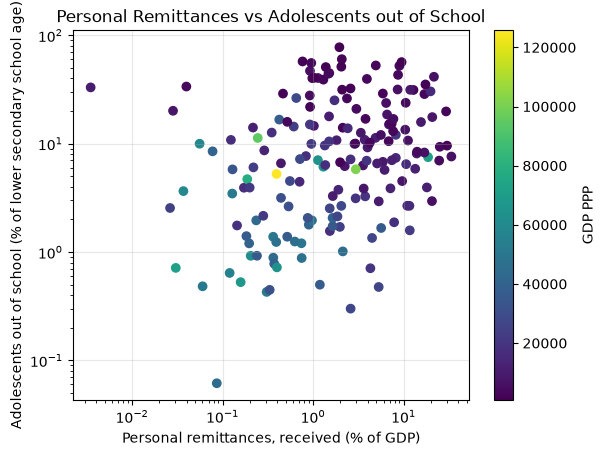

In [106]:
plt.scatter(country_means['remitt'], country_means['out_of_school'], c=country_means['gdp_ppp'])
plt.colorbar(label = 'GDP PPP')
plt.grid(alpha=0.3)
plt.xlabel('Personal remittances, received (% of GDP)')
plt.ylabel('Adolescents out of school (% of lower secondary school age)')
plt.title('Personal Remittances vs Adolescents out of School')
plt.xscale('log')
plt.yscale('log')
plt.show()


In [107]:
print(country_means[['remitt', 'out_of_school', 'gdp_ppp']].corr())
print(country_means[['remitt', 'out_of_school', 'gdp_ppp']].corr(method='spearman'))

                 remitt  out_of_school   gdp_ppp
remitt         1.000000       0.077079 -0.331933
out_of_school  0.077079       1.000000 -0.491338
gdp_ppp       -0.331933      -0.491338  1.000000
                 remitt  out_of_school   gdp_ppp
remitt         1.000000       0.292137 -0.512677
out_of_school  0.292137       1.000000 -0.764143
gdp_ppp       -0.512677      -0.764143  1.000000


This preliminary analysis does not do much to show us how changes in remittances correlate with changes in out of school rates for adolescents. This is largely because we are relying on averages, and do not control for income. This scatter plot only tells us that poor countries tend to have higher out of school rates and remittances. Our question has not yet been satisfied, but it does give us insights into what we need to control for. Using the world bank meta data, the next step is to control for country income status. We can also look at within country changes (deviations from the 25 year average) as another mechanism for determining relationships between our variables of interest.

In [108]:
within = countries.dropna(subset = ['remitt', 'out_of_school']).copy()
within['remitt_within'] = within['remitt'] - within.groupby("Country Name")['remitt'].transform('mean')
within['oos_within'] = within['out_of_school'] - within.groupby("Country Name")['out_of_school'].transform('mean')
within

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend,remitt_within,oos_within
10640,Aruba,ABW,2000,0.057850,13.717770,30245.706973,90588.0,91.580200,4.714680,-0.070943,7.922882
10645,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.330450,5.709664,3.181901
10649,Argentina,ARG,2000,0.030381,2.072500,11499.982800,37213984.0,96.214119,4.580310,-0.114107,0.312659
10666,Belize,BLZ,2000,2.185006,7.045090,7543.734472,240799.0,67.703018,3.683570,-1.807075,-2.191767
10668,Bolivia,BOL,2000,1.510743,2.761390,4113.042451,8606326.0,72.757637,NaN,-2.050527,-3.540569
...,...,...,...,...,...,...,...,...,...,...,...
17272,Ukraine,UKR,2024,6.288193,10.486900,18636.136719,37860221.0,86.169502,NaN,0.130471,4.757543
17276,Uzbekistan,UZB,2024,13.661665,3.001586,12518.432303,36361859.0,96.839922,NaN,4.030431,-1.517434
17284,Samoa,WSM,2024,24.006325,0.792427,8750.625410,218019.0,NaN,5.456166,3.447151,-2.162276
17288,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN,0.802993,-3.559357


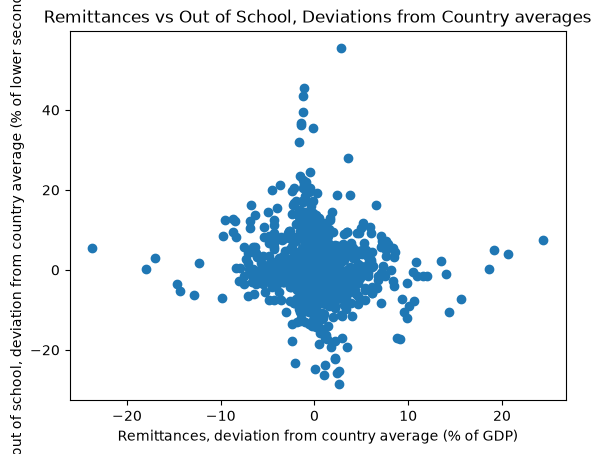

In [109]:
plt.scatter(within['remitt_within'], within['oos_within'])

plt.xlabel('Remittances, deviation from country average (% of GDP)')
plt.ylabel('Adolescents out of school, deviation from country average (% of lower secondary school age)')
plt.title('Remittances vs Out of School, Deviations from Country averages')
plt.show()

We will begin our exclusions. For starters, we will exclude high income countries. This is because we are interested in testing countries where households face budget constraints, and how remittances affect decision making regarding child school attendance. Next, we will run analysis with multiple exclusions based on the number of observations, with a bare minimum of 2 observations. This is because there needs to be some within country variation for the analysis to work properly, but we also want to be sure we are not arbitrarily excluding large shares of our sample.

In [110]:
meta = pd.read_csv('RemByGDP/Metadata_Country_API_BX.TRF.PWKR.DT.GD.ZS_DS2_en_csv_v2_59442.csv')
meta.head()

,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,Middle East & North Africa,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [111]:
# drop last three columns, will not be useful for our analysis
meta_df = meta.drop(columns=['SpecialNotes', 'TableName', 'Unnamed: 5'])

In [112]:
countries.shape

(5425, 9)

In [113]:
countries = pd.merge(countries, meta_df[['Country Code', 'Region', 'IncomeGroup']], on = "Country Code", how = 'left')
countries.shape

(5425, 11)

In [114]:
countries

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend,Region,IncomeGroup
0,Aruba,ABW,2000,0.057850,13.717770,30245.706973,90588.0,91.580200,4.71468,Latin America & Caribbean,High income
1,Afghanistan,AFG,2000,NaN,NaN,813.550256,20130327.0,NaN,NaN,Middle East & North Africa,Low income
2,Angola,AGO,2000,NaN,NaN,3689.537808,16194869.0,13.369070,2.60753,Sub-Saharan Africa,Lower middle income
3,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.33045,Europe & Central Asia,Upper middle income
4,Andorra,AND,2000,NaN,NaN,33458.118162,65685.0,NaN,NaN,Europe & Central Asia,High income
...,...,...,...,...,...,...,...,...,...,...,...
5420,Kosovo,XKX,2024,17.287446,NaN,17890.360099,1594353.0,NaN,NaN,Europe & Central Asia,Upper middle income
5421,"Yemen, Rep.",YEM,2024,NaN,NaN,NaN,40583164.0,NaN,NaN,Middle East & North Africa,Low income
5422,South Africa,ZAF,2024,0.213233,NaN,15478.645679,64007187.0,NaN,6.02110,Sub-Saharan Africa,Upper middle income
5423,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN,Sub-Saharan Africa,Lower middle income


In [115]:
countries_nohigh = countries[~countries['IncomeGroup'].isin(['High income'])].copy()


In [116]:
within2 = countries_nohigh.dropna(subset = ['remitt', 'out_of_school']).copy()
within2['remitt_within'] = within2['remitt'] - within2.groupby("Country Name")['remitt'].transform('mean')
within2['oos_within'] = within2['out_of_school'] - within2.groupby("Country Name")['out_of_school'].transform('mean')
within2

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend,Region,IncomeGroup,remitt_within,oos_within
3,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.330450,Europe & Central Asia,Upper middle income,5.709664,3.181901
6,Argentina,ARG,2000,0.030381,2.072500,11499.982800,37213984.0,96.214119,4.580310,Latin America & Caribbean,Upper middle income,-0.114107,0.312659
23,Belize,BLZ,2000,2.185006,7.045090,7543.734472,240799.0,67.703018,3.683570,Latin America & Caribbean,Upper middle income,-1.807075,-2.191767
25,Bolivia,BOL,2000,1.510743,2.761390,4113.042451,8606326.0,72.757637,NaN,Latin America & Caribbean,Lower middle income,-2.050527,-3.540569
30,Botswana,BWA,2000,0.320315,9.417700,9380.376072,1677382.0,76.196823,NaN,Sub-Saharan Africa,Upper middle income,0.031539,0.745650
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5409,Ukraine,UKR,2024,6.288193,10.486900,18636.136719,37860221.0,86.169502,NaN,Europe & Central Asia,Upper middle income,0.130471,4.757543
5412,Uzbekistan,UZB,2024,13.661665,3.001586,12518.432303,36361859.0,96.839922,NaN,Europe & Central Asia,Lower middle income,4.030431,-1.517434
5419,Samoa,WSM,2024,24.006325,0.792427,8750.625410,218019.0,NaN,5.456166,East Asia & Pacific,Upper middle income,3.447151,-2.162276
5423,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN,Sub-Saharan Africa,Lower middle income,0.802993,-3.559357


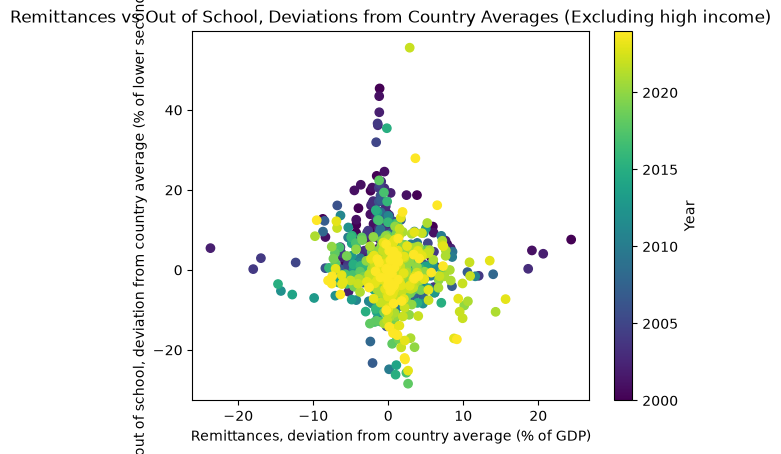

In [117]:
plt.scatter(within2['remitt_within'], within2['oos_within'], c= within2['year'])
plt.colorbar(label = 'Year')
plt.xlabel('Remittances, deviation from country average (% of GDP)')
plt.ylabel('Adolescents out of school, deviation from country average (% of lower secondary school age)')
plt.title('Remittances vs Out of School, Deviations from Country Averages (Excluding high income)')
plt.show()

In [118]:
# Do min observations first, then look at changes in both
# Rows where both remittances and out-of-school are present
both = countries_nohigh.dropna(subset=['remitt', 'out_of_school']).copy()

# Number of years each country has both
obs_counts = both.groupby('Country Name')['year'].count()
obs_counts.describe()


count    111.000000
mean      13.549550
std        6.819409
min        1.000000
25%        8.500000
50%       13.000000
75%       19.000000
max       25.000000
Name: year, dtype: float64

In [119]:
for k in [2, 3, 5, 10]:
    kept = (obs_counts >= k).sum()
    rows = both[both['Country Name'].isin(obs_counts[obs_counts >= k].index)].shape[0]
    print(f"min {k} obs: {kept} of {len(obs_counts)} countries, {rows} observations")


min 2 obs: 105 of 111 countries, 1498 observations
min 3 obs: 105 of 111 countries, 1498 observations
min 5 obs: 98 of 111 countries, 1472 observations
min 10 obs: 76 of 111 countries, 1310 observations


In [120]:
both['n_obs'] = both.groupby('Country Name')['year'].transform('count')
within_min2 = both[both['n_obs'] >= 2].copy()


In [121]:
within_min2_dev = within_min2.dropna(subset = ['remitt', 'out_of_school']).copy()
within_min2_dev['remitt_within'] = within_min2_dev['remitt'] - within_min2_dev.groupby("Country Name")['remitt'].transform('mean')
within_min2_dev['oos_within'] = within_min2_dev['out_of_school'] - within_min2_dev.groupby("Country Name")['out_of_school'].transform('mean')
within_min2_dev

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend,Region,IncomeGroup,n_obs,remitt_within,oos_within
3,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.330450,Europe & Central Asia,Upper middle income,13,5.709664,3.181901
6,Argentina,ARG,2000,0.030381,2.072500,11499.982800,37213984.0,96.214119,4.580310,Latin America & Caribbean,Upper middle income,24,-0.114107,0.312659
23,Belize,BLZ,2000,2.185006,7.045090,7543.734472,240799.0,67.703018,3.683570,Latin America & Caribbean,Upper middle income,23,-1.807075,-2.191767
25,Bolivia,BOL,2000,1.510743,2.761390,4113.042451,8606326.0,72.757637,NaN,Latin America & Caribbean,Lower middle income,25,-2.050527,-3.540569
30,Botswana,BWA,2000,0.320315,9.417700,9380.376072,1677382.0,76.196823,NaN,Sub-Saharan Africa,Upper middle income,7,0.031539,0.745650
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5409,Ukraine,UKR,2024,6.288193,10.486900,18636.136719,37860221.0,86.169502,NaN,Europe & Central Asia,Upper middle income,22,0.130471,4.757543
5412,Uzbekistan,UZB,2024,13.661665,3.001586,12518.432303,36361859.0,96.839922,NaN,Europe & Central Asia,Lower middle income,18,4.030431,-1.517434
5419,Samoa,WSM,2024,24.006325,0.792427,8750.625410,218019.0,NaN,5.456166,East Asia & Pacific,Upper middle income,17,3.447151,-2.162276
5423,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN,Sub-Saharan Africa,Lower middle income,4,0.802993,-3.559357


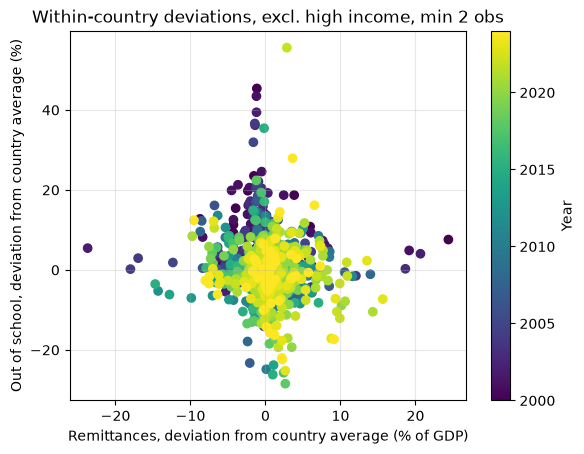

               remitt_within  oos_within
remitt_within       1.000000   -0.082705
oos_within         -0.082705    1.000000
               remitt_within  oos_within
remitt_within       1.000000   -0.083319
oos_within         -0.083319    1.000000


In [122]:
plt.scatter(within_min2_dev['remitt_within'], within_min2_dev['oos_within'], c=within_min2_dev['year'])
plt.colorbar(label='Year')
plt.xlabel('Remittances, deviation from country average (% of GDP)')
plt.ylabel('Out of school, deviation from country average (%)')
plt.title('Within-country deviations, excl. high income, min 2 obs')
plt.grid(alpha=0.3)
plt.show()

print(within_min2_dev[['remitt_within', 'oos_within']].corr())
print(within_min2_dev[['remitt_within', 'oos_within']].corr(method='spearman'))


In [123]:
# Calculate the correlations for each k value of minimum observations. This will help us understand how the correlation changes as we require more data points for each country. 
def within_dev(df, k):
    d = df[df['n_obs'] >= k].copy()
    for col, new in [('remitt', 'remitt_within'), ('out_of_school', 'oos_within')]:
        d[new] = d[col] - d.groupby('Country Name')[col].transform('mean')
    return d

for k in [2, 3, 5, 10]:
    d = within_dev(both, k)
    r = d['remitt_within'].corr(d['oos_within'])
    print(f"min {k}: {d['Country Name'].nunique()} countries, {len(d)} obs, r = {r:.3f}")


min 2: 105 countries, 1498 obs, r = -0.083
min 3: 105 countries, 1498 obs, r = -0.083
min 5: 98 countries, 1472 obs, r = -0.082
min 10: 76 countries, 1310 obs, r = -0.085


Now, we have made our main exclusions, and we need to begin isolating the relationship between remittances and out of school rates. The cutoffs show that countries with few observations are not driving correlation, and the agreement between Pearson and Spearman shows that outliers are not either. All correlations stayed within r = -0.082 and -0.085, which is a very weak, negative correlation. Interestingly, though, there has been a sign flip. Cell 22 showed us that there was a weak, positive (+0.08, and +0.29 Spearman) correlation across country averages. However, the correlation found when comparing within country deviations has a negative, though weak, correlation. This suggests that the cross-country analysis was confounded, and justifies a fixed-effects regression. 

The aim of this regression is to properly compare each country with itself using country fixed effects. It is not helpful to compare each country with each other, as regions such as Sub-Saharan Africa have higher out-of-school rates than Latin America, for example. This can confound our results if those Latin American countries are high remittance, when really we are interested in how changes in a country's remittance rates affect its own education levels, not how different countries compare. We also need a mechanism to control for global shocks (such as the financial crisis and COVID-19) that had a global impact, and a mechanism for controlling for GDP beyond simply excluding more countries. We will do this by using log GDP as a control, as when countries get richer, remittances and out of school rates can change for changes in income instead of remittances. We need to cluster by country using clustered standard errors, as each data point is not fully independent. Remittance and out of school levels in Nigeria in 2012 may depend on schocks that also effect those levels in Nigeria in 2011, but may not depend on shocks in India in 2002. For this reason, we need to cluster by country so that each country is treated as an independent unit, not each single point of data.

In [124]:
# Building the regression model:
reg = within_min2.copy()

In [125]:
reg['log_gdp'] = np.log(reg['gdp_ppp'])

In [126]:
reg = reg.dropna(subset = ['remitt', 'out_of_school', 'log_gdp'])

In [127]:
reg

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend,Region,IncomeGroup,n_obs,log_gdp
3,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.330450,Europe & Central Asia,Upper middle income,13,8.288482
6,Argentina,ARG,2000,0.030381,2.072500,11499.982800,37213984.0,96.214119,4.580310,Latin America & Caribbean,Upper middle income,24,9.350101
23,Belize,BLZ,2000,2.185006,7.045090,7543.734472,240799.0,67.703018,3.683570,Latin America & Caribbean,Upper middle income,23,8.928473
25,Bolivia,BOL,2000,1.510743,2.761390,4113.042451,8606326.0,72.757637,NaN,Latin America & Caribbean,Lower middle income,25,8.321918
30,Botswana,BWA,2000,0.320315,9.417700,9380.376072,1677382.0,76.196823,NaN,Sub-Saharan Africa,Upper middle income,7,9.146375
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5409,Ukraine,UKR,2024,6.288193,10.486900,18636.136719,37860221.0,86.169502,NaN,Europe & Central Asia,Upper middle income,22,9.832858
5412,Uzbekistan,UZB,2024,13.661665,3.001586,12518.432303,36361859.0,96.839922,NaN,Europe & Central Asia,Lower middle income,18,9.434957
5419,Samoa,WSM,2024,24.006325,0.792427,8750.625410,218019.0,NaN,5.456166,East Asia & Pacific,Upper middle income,17,9.076880
5423,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN,Sub-Saharan Africa,Lower middle income,4,8.347831


In [128]:
reg['Country Code'].nunique()

104

In [143]:
# We are going to build two main models, one just focusing on the relationship between remittances and out-of-school rates, and another using GDP as a control variable.
# This allows us to see if the relationship between remittances and out-of-school rates survives holding GDP constant.

import statsmodels.formula.api as smf 

model1 = smf.ols('out_of_school ~ remitt + C(Q("Country Code")) + C(year)', data=reg)
groups = pd.factorize(reg['Country Code'])[0]
res1 = model1.fit(cov_type='cluster', cov_kwds={'groups': groups})

print("res1 parameters:", res1.params['remitt'])
print("res1 p-values:", res1.pvalues['remitt'])
print("res1 R-squared:", res1.rsquared)
print("res1 standard errors:", res1.bse['remitt'])

res1 parameters: -0.1305195169494957
res1 p-values: 0.24548668477280833
res1 R-squared: 0.8698380463189459
res1 standard errors: 0.11238295782931339


In [145]:
# Build model 2, which includes GDP as a control variable. This will allow us to see if the relationship between remittances and out-of-school rates survives holding GDP constant.

model2 = smf.ols('out_of_school ~ remitt + log_gdp + C(Q("Country Code")) + C(year)', data=reg)
res2 = model2.fit(cov_type='cluster', cov_kwds={'groups': groups})

print("res2 parameters:", res2.params['remitt'])
print("res2 p-values:", res2.pvalues['remitt'])
print("res2 R-squared:", res2.rsquared)
print("res2 standard errors:", res2.bse['remitt'])

res2 parameters: -0.14840114041675412
res2 p-values: 0.2109548260659131
res2 R-squared: 0.8704928456179032
res2 standard errors: 0.11863130032859012
